In [1]:
# ============================================================
# CELL 1 ▸ Install + Imports
# ============================================================
import subprocess, sys
for pkg in ['pandas','numpy','scipy','matplotlib','seaborn',
            'scikit-learn','xgboost','tqdm']:
    try: __import__('sklearn' if pkg=='scikit-learn' else pkg)
    except ImportError:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg],
                              stdout=subprocess.DEVNULL,stderr=subprocess.DEVNULL)

import os, json, pickle, zipfile, warnings, time
import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, accuracy_score,
    classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight
import xgboost as xgb

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':150,'savefig.dpi':300,'font.size':11,
                     'axes.titlesize':13,'savefig.bbox':'tight'})
SEED = 42
np.random.seed(SEED)
print(f'sklearn {__import__("sklearn").__version__} | xgb {xgb.__version__}')
print('Imports complete.')

sklearn 1.6.1 | xgb 3.2.0
Imports complete.


In [2]:
# ============================================================
# CELL 2 ▸ Configuration
# ============================================================
# ⚙️  Set INPUT_DIR to your Kaggle dataset containing both files.

INPUT_DIR    = '/kaggle/input/your-p1p2-dataset'
FEATURES_CSV = os.path.join(INPUT_DIR, '/kaggle/input/datasets/tarek1074/part2-features-complete/features_all.csv')
FOLDS_CSV    = os.path.join(INPUT_DIR, '/kaggle/input/datasets/tarek1074/part1-outputs/fold_assignments.csv')

WORK_DIR = '/kaggle/working'
OUT_DIR  = os.path.join(WORK_DIR, 'part3_ml')
FIG_DIR  = os.path.join(OUT_DIR,  'figures')
MDL_DIR  = os.path.join(OUT_DIR,  'models')
for d in [OUT_DIR, FIG_DIR, MDL_DIR]:
    os.makedirs(d, exist_ok=True)

N_FOLDS = 5
CLASS_NAMES = [
    'Bangla_Band_Collection', 'Bangla_ancholik',
    'Bangla_baby_rhymes',     'Bangla_rabindra_sangeet',
    'Bangla_romantic',        'Classic_Songs_',
    'Islamic_Melody',         'Nazrul_Geeti_',
]
CLASS_SHORT = {
    'Bangla_Band_Collection':'Band', 'Bangla_ancholik':'Ancholik',
    'Bangla_baby_rhymes':'Rhymes',   'Bangla_rabindra_sangeet':'Rabindra',
    'Bangla_romantic':'Romantic',    'Classic_Songs_':'Classic',
    'Islamic_Melody':'Islamic',      'Nazrul_Geeti_':'Nazrul',
}
N_CLASSES   = len(CLASS_NAMES)
SHORT_NAMES = [CLASS_SHORT[c] for c in CLASS_NAMES]
META_COLS   = {'filepath','label','coarse','song_id',
               'seg_idx','seg_duration_s','fold','duration_s','n_segs_est'}
MODEL_PAL   = {'SVM':'#4C72B0','RandomForest':'#DD8452','XGBoost':'#55A868'}
CLASS_PAL   = dict(zip(CLASS_NAMES, sns.color_palette('tab10',8)))
CV_RESULTS  = {}

print('Configuration loaded.')
print(f'  INPUT_DIR : {INPUT_DIR}')
print(f'  OUT_DIR   : {OUT_DIR}')

Configuration loaded.
  INPUT_DIR : /kaggle/input/your-p1p2-dataset
  OUT_DIR   : /kaggle/working/part3_ml


In [3]:
# ============================================================
# CELL 3 ▸ Load + Merge Data
# ============================================================
print('Loading features_all.csv ...')
feat_df = pd.read_csv(FEATURES_CSV)
feat_cols = [c for c in feat_df.columns if c not in META_COLS]
feat_df[feat_cols] = (feat_df[feat_cols]
                      .replace([float('inf'),float('-inf')], float('nan'))
                      .fillna(0.0))
print(f'  {len(feat_df):,} segments  x  {len(feat_cols)} features')

print('Loading fold_assignments.csv ...')
fold_df = pd.read_csv(FOLDS_CSV)[['filepath','label','fold']]
print(f'  {len(fold_df):,} files  x  {N_FOLDS} folds')

# Merge on filepath (all segments from a file get the same fold)
df = feat_df.merge(fold_df[['filepath','fold']], on='filepath', how='left')
missing_fold = df['fold'].isna().sum()
if missing_fold:
    print(f'  ⚠️  {missing_fold} segments missing fold — check filepath alignment')
    df['fold'] = df['fold'].fillna(0).astype(int)
else:
    df['fold'] = df['fold'].astype(int)
    print(f'  ✅ All segments have fold assignments')

# Label encode
le = LabelEncoder().fit(CLASS_NAMES)
df['label_id'] = le.transform(df['label'])

# Verify all 8 classes in every fold
print()
for k in range(N_FOLDS):
    classes_in_fold = set(df[df['fold']==k]['label'].unique())
    missing = set(CLASS_NAMES) - classes_in_fold
    status = 'PASS' if not missing else f'FAIL missing {missing}'
    print(f'  Fold {k}: [{status}]  {len(df[df["fold"]==k]):,} segments')

print(f'\nTotal: {len(df):,} segments  |  {df["filepath"].nunique():,} files')

Loading features_all.csv ...
  60,395 segments  x  237 features
Loading fold_assignments.csv ...
  1,870 files  x  5 folds
  ✅ All segments have fold assignments

  Fold 0: [PASS]  11,542 segments
  Fold 1: [PASS]  12,878 segments
  Fold 2: [PASS]  11,751 segments
  Fold 3: [PASS]  13,616 segments
  Fold 4: [PASS]  10,608 segments

Total: 60,395 segments  |  1,870 files


In [4]:
# ============================================================
# CELL 4 ▸ CV Utilities
# ============================================================

def get_fold_xy(df, feat_cols, fold_k):
    """Return (X_train, y_train, X_test, y_test, train_labels_str)."""
    tr = df[df['fold'] != fold_k]
    te = df[df['fold'] == fold_k]
    return (tr[feat_cols].values.astype('float32'),
            tr['label_id'].values,
            te[feat_cols].values.astype('float32'),
            te['label_id'].values,
            tr['label'].values)


def compute_metrics(y_true, y_pred, short_names=SHORT_NAMES):
    mf1 = float(f1_score(y_true, y_pred, average='macro',    zero_division=0))
    wf1 = float(f1_score(y_true, y_pred, average='weighted', zero_division=0))
    acc = float(accuracy_score(y_true, y_pred))
    rpt = classification_report(y_true, y_pred,
                                 target_names=short_names,
                                 output_dict=True, zero_division=0)
    pcf1 = [rpt[s]['f1-score'] for s in short_names]
    return {'macro_f1':mf1,'weighted_f1':wf1,'accuracy':acc,'per_class_f1':pcf1}


def summarise_cv(fold_metrics, model_name):
    mf1s = np.array([m['macro_f1']    for m in fold_metrics])
    wf1s = np.array([m['weighted_f1'] for m in fold_metrics])
    accs = np.array([m['accuracy']    for m in fold_metrics])
    n    = len(mf1s)
    t95  = scipy_stats.t.ppf(0.975, df=n-1)
    ci   = lambda a: float(t95 * a.std(ddof=1) / np.sqrt(n))

    s = {
        'model'           : model_name,
        'n_folds'         : n,
        'macro_f1_mean'   : round(float(mf1s.mean()), 4),
        'macro_f1_std'    : round(float(mf1s.std(ddof=1)), 4),
        'macro_f1_ci95'   : round(ci(mf1s), 4),
        'macro_f1_min'    : round(float(mf1s.min()), 4),
        'macro_f1_max'    : round(float(mf1s.max()), 4),
        'weighted_f1_mean': round(float(wf1s.mean()), 4),
        'weighted_f1_std' : round(float(wf1s.std(ddof=1)), 4),
        'accuracy_mean'   : round(float(accs.mean()), 4),
        'accuracy_std'    : round(float(accs.std(ddof=1)), 4),
        'per_fold_macro_f1': mf1s.tolist(),
    }
    m, sd, ci95 = s['macro_f1_mean'], s['macro_f1_std'], s['macro_f1_ci95']
    print(f'  {model_name}  Macro-F1: {m:.4f} +/- {sd:.4f}  '
          f'95%CI [{m-ci95:.4f}, {m+ci95:.4f}]')
    print(f'    Per fold: {[round(v,4) for v in mf1s.tolist()]}')
    return s


def make_class_weight_dict(y_train):
    """Balanced class weights from training labels only."""
    cw  = compute_class_weight('balanced',
                               classes=np.arange(N_CLASSES), y=y_train)
    return {i: float(cw[i]) for i in range(N_CLASSES)}


def make_sample_weights_sqrt(y_train):
    """Sqrt inverse frequency weights for XGBoost sample_weight."""
    counts = np.array([(y_train==i).sum() for i in range(N_CLASSES)], dtype=float)
    w = np.sqrt(counts.max() / (counts + 1e-8))
    w = w / w.mean()
    return np.array([w[yi] for yi in y_train], dtype=float)


print('CV utilities ready.')

CV utilities ready.


In [5]:
# ============================================================
# CELL 5 ▸ SVM (RBF Kernel) — 5-Fold CV
# ============================================================
# Uses PCA (95% variance) for speed. class_weight='balanced'.
# Expected time: 60–120 min total.

print('='*55)
print('  SVM (RBF) — 5-Fold CV')
print('='*55)

svm_fold_metrics = []
best_svm, best_svm_f1 = None, -1

for k in range(N_FOLDS):
    t0 = time.time()
    X_tr, y_tr, X_te, y_te, lbl_tr = get_fold_xy(df, feat_cols, k)

    # Scale (fit on train only)
    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_te_s = sc.transform(X_te)

    # PCA (fit on train only)
    pca_full = PCA(random_state=SEED)
    pca_full.fit(X_tr_s)
    n_comp = int(np.searchsorted(pca_full.explained_variance_ratio_.cumsum(), 0.95)) + 1
    pca = PCA(n_components=n_comp, random_state=SEED)
    X_tr_p = pca.fit_transform(X_tr_s)
    X_te_p = pca.transform(X_te_s)

    cw = make_class_weight_dict(y_tr)
    clf = SVC(kernel='rbf', C=10, gamma='scale',
              class_weight=cw, probability=True,
              random_state=SEED, decision_function_shape='ovr')
    clf.fit(X_tr_p, y_tr)

    y_pred = clf.predict(X_te_p)
    m = compute_metrics(y_te, y_pred)
    svm_fold_metrics.append(m)

    if m['macro_f1'] > best_svm_f1:
        best_svm_f1 = m['macro_f1']
        best_svm = {'clf':clf,'scaler':sc,'pca':pca}

    elapsed = time.time()-t0
    print(f'  Fold {k+1}/5  Macro-F1={m["macro_f1"]:.4f}  '
          f'Acc={m["accuracy"]:.4f}  PCA={n_comp}  ({elapsed/60:.1f} min)')

print()
svm_summary = summarise_cv(svm_fold_metrics, 'SVM')
CV_RESULTS['SVM'] = {'summary':svm_summary, 'fold_metrics':svm_fold_metrics}

# Save best fold model
with open(os.path.join(MDL_DIR,'svm.pkl'),'wb') as f:
    pickle.dump(best_svm, f)
print(f'  Best SVM saved (fold F1={best_svm_f1:.4f})')

  SVM (RBF) — 5-Fold CV
  Fold 1/5  Macro-F1=0.6655  Acc=0.6820  PCA=158  (31.0 min)
  Fold 2/5  Macro-F1=0.6991  Acc=0.7122  PCA=158  (28.1 min)
  Fold 3/5  Macro-F1=0.6900  Acc=0.7118  PCA=157  (32.8 min)
  Fold 4/5  Macro-F1=0.6817  Acc=0.7142  PCA=158  (26.7 min)
  Fold 5/5  Macro-F1=0.6940  Acc=0.7101  PCA=158  (33.1 min)

  SVM  Macro-F1: 0.6861 +/- 0.0132  95%CI [0.6698, 0.7024]
    Per fold: [0.6655, 0.6991, 0.69, 0.6817, 0.694]
  Best SVM saved (fold F1=0.6991)


In [6]:
# ============================================================
# CELL 6 ▸ Random Forest — 5-Fold CV
# ============================================================
# Full 237 features, balanced_subsample class weights.
# Expected time: 10–20 min total.

print('='*55)
print('  Random Forest — 5-Fold CV')
print('='*55)

rf_fold_metrics = []
best_rf, best_rf_f1 = None, -1

for k in range(N_FOLDS):
    t0 = time.time()
    X_tr, y_tr, X_te, y_te, lbl_tr = get_fold_xy(df, feat_cols, k)

    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_te_s = sc.transform(X_te)

    clf = RandomForestClassifier(
        n_estimators=500, max_depth=None,
        min_samples_leaf=2, max_features='sqrt',
        class_weight='balanced_subsample',
        n_jobs=-1, random_state=SEED+k)
    clf.fit(X_tr_s, y_tr)

    y_pred = clf.predict(X_te_s)
    m = compute_metrics(y_te, y_pred)
    rf_fold_metrics.append(m)

    if m['macro_f1'] > best_rf_f1:
        best_rf_f1 = m['macro_f1']
        best_rf = {'clf':clf,'scaler':sc}

    elapsed = time.time()-t0
    print(f'  Fold {k+1}/5  Macro-F1={m["macro_f1"]:.4f}  '
          f'Acc={m["accuracy"]:.4f}  ({elapsed/60:.1f} min)')

print()
rf_summary = summarise_cv(rf_fold_metrics, 'RandomForest')
CV_RESULTS['RandomForest'] = {'summary':rf_summary, 'fold_metrics':rf_fold_metrics}

with open(os.path.join(MDL_DIR,'rf.pkl'),'wb') as f:
    pickle.dump(best_rf, f)
print(f'  Best RF saved (fold F1={best_rf_f1:.4f})')

  Random Forest — 5-Fold CV
  Fold 1/5  Macro-F1=0.6272  Acc=0.6485  (5.3 min)
  Fold 2/5  Macro-F1=0.6448  Acc=0.6684  (5.1 min)
  Fold 3/5  Macro-F1=0.6381  Acc=0.6703  (5.3 min)
  Fold 4/5  Macro-F1=0.6391  Acc=0.6854  (5.0 min)
  Fold 5/5  Macro-F1=0.6416  Acc=0.6719  (5.4 min)

  RandomForest  Macro-F1: 0.6382 +/- 0.0066  95%CI [0.6299, 0.6465]
    Per fold: [0.6272, 0.6448, 0.6381, 0.6391, 0.6416]
  Best RF saved (fold F1=0.6448)


In [7]:
# ============================================================
# CELL 7 ▸ XGBoost — 5-Fold CV
# ============================================================
# Full 237 features, sqrt-inverse-frequency sample weights.
# Expected time: 15–30 min total.

print('='*55)
print('  XGBoost — 5-Fold CV')
print('='*55)

xgb_fold_metrics = []
best_xgb, best_xgb_f1 = None, -1

for k in range(N_FOLDS):
    t0 = time.time()
    X_tr, y_tr, X_te, y_te, lbl_tr = get_fold_xy(df, feat_cols, k)

    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_te_s = sc.transform(X_te)

    sw = make_sample_weights_sqrt(y_tr)

    clf = xgb.XGBClassifier(
        n_estimators=300, max_depth=6,
        learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, objective='multi:softmax',
        num_class=N_CLASSES, eval_metric='mlogloss',
        tree_method='hist', n_jobs=-1,
        random_state=SEED+k, verbosity=0)
    clf.fit(X_tr_s, y_tr, sample_weight=sw, verbose=False)

    y_pred = clf.predict(X_te_s)
    m = compute_metrics(y_te, y_pred)
    xgb_fold_metrics.append(m)

    if m['macro_f1'] > best_xgb_f1:
        best_xgb_f1 = m['macro_f1']
        best_xgb = {'clf':clf,'scaler':sc}

    elapsed = time.time()-t0
    print(f'  Fold {k+1}/5  Macro-F1={m["macro_f1"]:.4f}  '
          f'Acc={m["accuracy"]:.4f}  ({elapsed/60:.1f} min)')

print()
xgb_summary = summarise_cv(xgb_fold_metrics, 'XGBoost')
CV_RESULTS['XGBoost'] = {'summary':xgb_summary, 'fold_metrics':xgb_fold_metrics}

best_xgb['clf'].save_model(os.path.join(MDL_DIR,'xgb.json'))
with open(os.path.join(MDL_DIR,'xgb_scaler.pkl'),'wb') as f:
    pickle.dump(best_xgb['scaler'], f)
print(f'  Best XGBoost saved (fold F1={best_xgb_f1:.4f})')

  XGBoost — 5-Fold CV
  Fold 1/5  Macro-F1=0.6783  Acc=0.6871  (3.1 min)
  Fold 2/5  Macro-F1=0.7091  Acc=0.7191  (3.1 min)
  Fold 3/5  Macro-F1=0.7042  Acc=0.7214  (3.1 min)
  Fold 4/5  Macro-F1=0.6869  Acc=0.7150  (3.0 min)
  Fold 5/5  Macro-F1=0.7062  Acc=0.7193  (3.1 min)

  XGBoost  Macro-F1: 0.6969 +/- 0.0136  95%CI [0.6801, 0.7137]
    Per fold: [0.6783, 0.7091, 0.7042, 0.6869, 0.7062]
  Best XGBoost saved (fold F1=0.7091)


In [8]:
# ============================================================
# CELL 8 ▸ Results Summary
# ============================================================
def to_py(obj):
    if isinstance(obj,dict):       return {k:to_py(v) for k,v in obj.items()}
    if isinstance(obj,(list,tuple)):return [to_py(v) for v in obj]
    if isinstance(obj,np.ndarray): return obj.tolist()
    if isinstance(obj,(np.integer,)):  return int(obj)
    if isinstance(obj,(np.floating,)): return float(obj)
    return obj

with open(os.path.join(OUT_DIR,'part3_cv_results.json'),'w') as f:
    json.dump(to_py({k:{'summary':v['summary']} for k,v in CV_RESULTS.items()}),
              f, indent=2)

print('='*68)
print('  PAPER TABLE — ML Baselines 5-Fold CV (Test Macro-F1)')
print('='*68)
print(f'  {"Model":<15} {"Macro-F1":>22}  {"95% CI":>22}  '
      f'{"W-F1":>8}  {"Acc":>8}')
print(f'  {"-"*15} {"-"*22}  {"-"*22}  {"-"*8}  {"-"*8}')

for mname, res in CV_RESULTS.items():
    s  = res['summary']
    m  = s['macro_f1_mean']; sd = s['macro_f1_std']; ci = s['macro_f1_ci95']
    print(f'  {mname:<15} {m:.4f} +/- {sd:.4f}  '
          f'[{m-ci:.4f}, {m+ci:.4f}]  '
          f'{s["weighted_f1_mean"]:>8.4f}  {s["accuracy_mean"]:>8.4f}')

print()
print('Per-class Macro-F1 (mean across 5 folds):')
print(f'  {"Class":<12}', end='')
for m in CV_RESULTS: print(f'  {m:>14}', end='')
print()
for i,cls in enumerate(SHORT_NAMES):
    print(f'  {cls:<12}', end='')
    for mname,res in CV_RESULTS.items():
        vals = [m['per_class_f1'][i] for m in res['fold_metrics']]
        print(f'  {np.mean(vals):>7.4f}+/-{np.std(vals,ddof=1):.3f}', end='')
    print()

  PAPER TABLE — ML Baselines 5-Fold CV (Test Macro-F1)
  Model                         Macro-F1                  95% CI      W-F1       Acc
  --------------- ----------------------  ----------------------  --------  --------
  SVM             0.6861 +/- 0.0132  [0.6698, 0.7024]    0.7048    0.7061
  RandomForest    0.6382 +/- 0.0066  [0.6299, 0.6465]    0.6598    0.6689
  XGBoost         0.6969 +/- 0.0136  [0.6801, 0.7137]    0.7114    0.7124

Per-class Macro-F1 (mean across 5 folds):
  Class                    SVM    RandomForest         XGBoost
  Band           0.6238+/-0.033   0.6065+/-0.040   0.6307+/-0.047
  Ancholik       0.5964+/-0.063   0.5405+/-0.075   0.6051+/-0.062
  Rhymes         0.8487+/-0.031   0.8148+/-0.040   0.8443+/-0.037
  Rabindra       0.5308+/-0.049   0.4327+/-0.046   0.5965+/-0.041
  Romantic       0.5087+/-0.046   0.4871+/-0.048   0.5313+/-0.053
  Classic        0.6891+/-0.028   0.6555+/-0.034   0.6887+/-0.030
  Islamic        0.8698+/-0.016   0.8162+/-0.011   

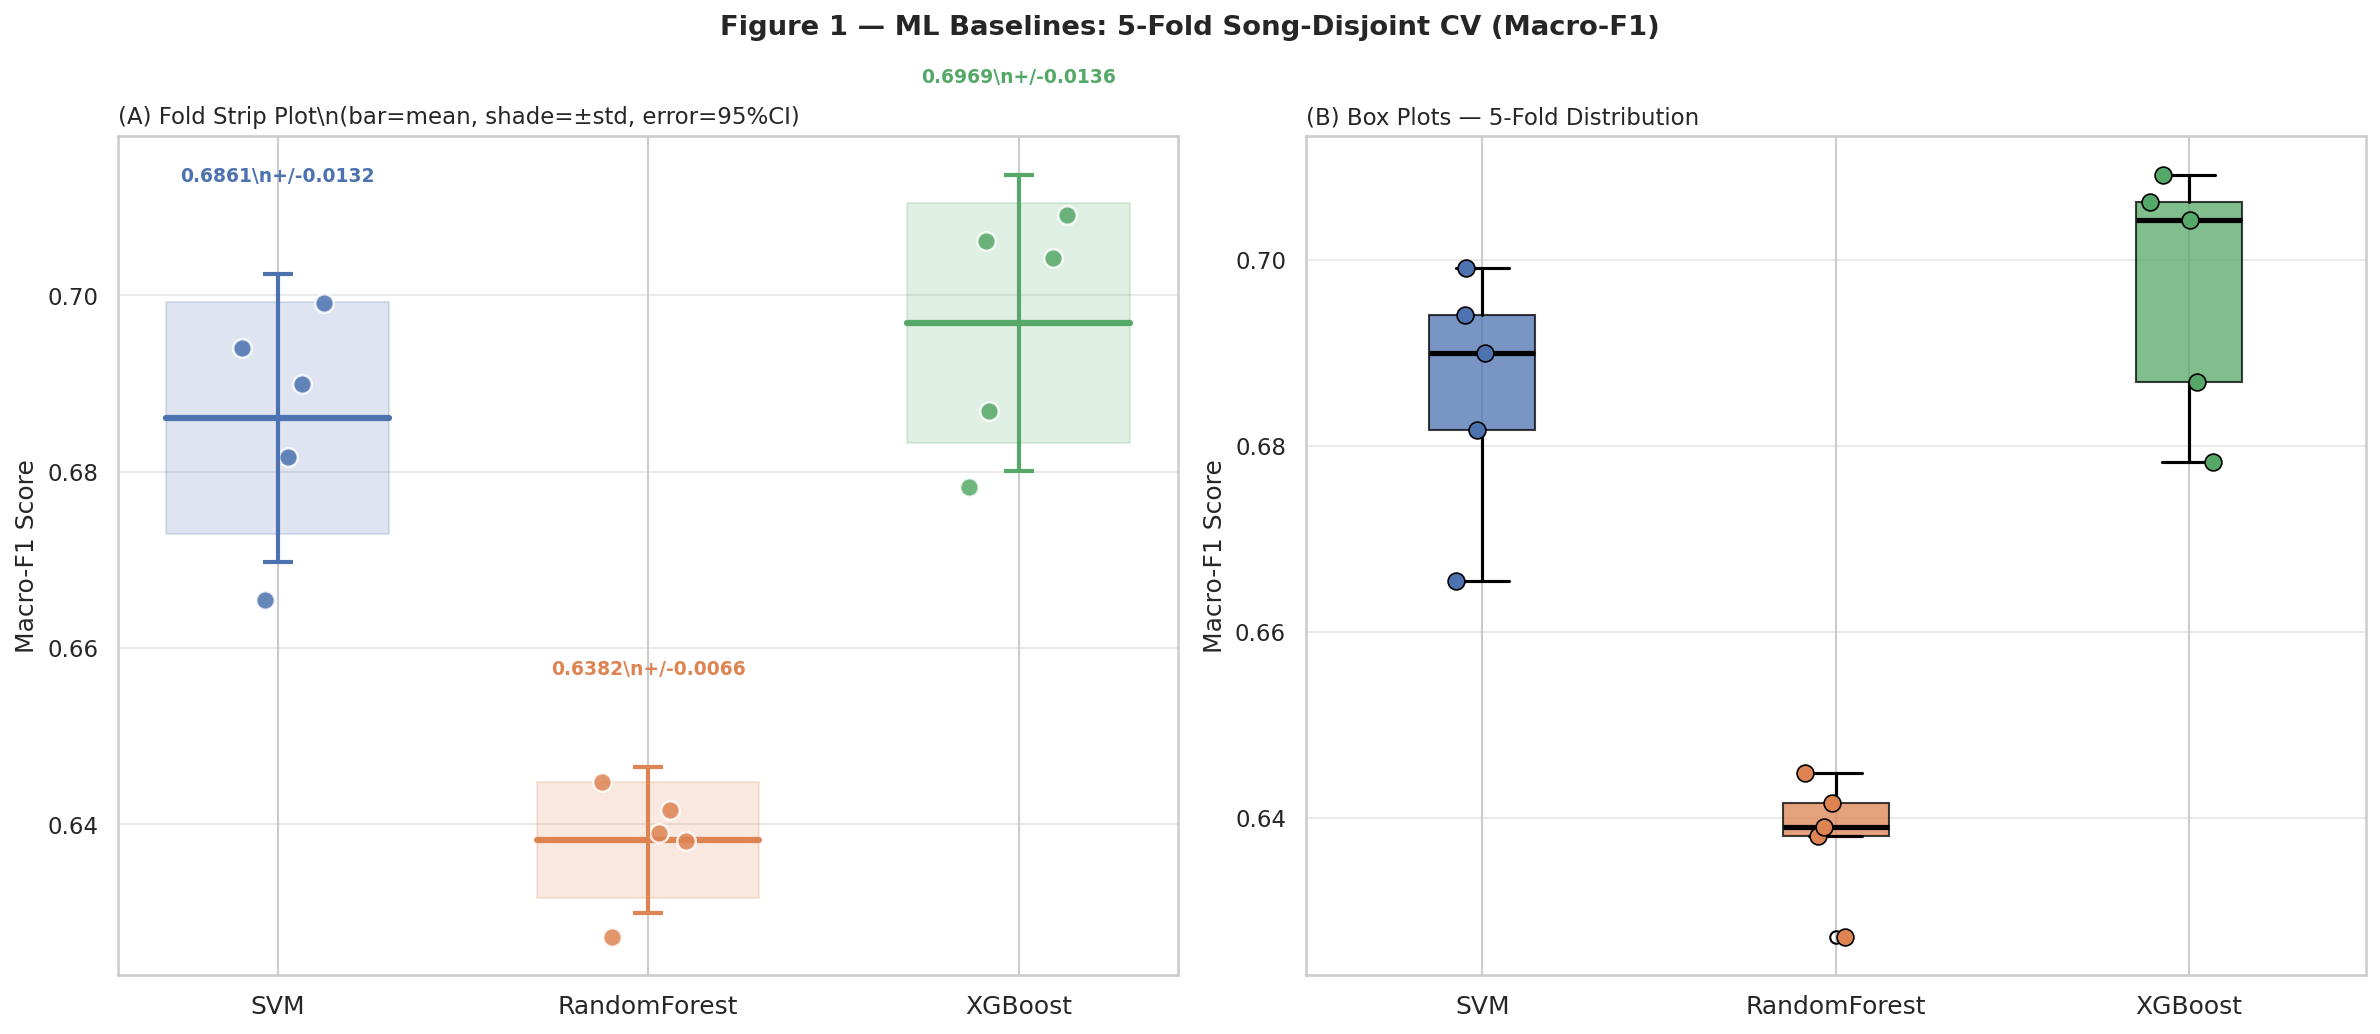

Saved: /kaggle/working/part3_ml/figures/fig01_cv_strip_box.png


In [9]:
# ============================================================
# CELL 9 ▸ Fig 1 — CV Strip Plot + Box Plot
# ============================================================
model_names = list(CV_RESULTS.keys())
n_m = len(model_names)
colors = [MODEL_PAL[m] for m in model_names]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Figure 1 — ML Baselines: 5-Fold Song-Disjoint CV (Macro-F1)',
             fontweight='bold')

# Panel A: strip plot with mean bar + CI
ax = axes[0]
rng = np.random.RandomState(SEED)
for xi, (mname, color) in enumerate(zip(model_names, colors)):
    folds_f1 = CV_RESULTS[mname]['summary']['per_fold_macro_f1']
    mean_f1  = CV_RESULTS[mname]['summary']['macro_f1_mean']
    std_f1   = CV_RESULTS[mname]['summary']['macro_f1_std']
    ci_f1    = CV_RESULTS[mname]['summary']['macro_f1_ci95']

    jitter = rng.uniform(-0.14, 0.14, len(folds_f1))
    ax.scatter([xi+j for j in jitter], folds_f1,
               s=80, color=color, alpha=0.85, zorder=4,
               edgecolors='white', linewidth=1.2)
    ax.plot([xi-0.3, xi+0.3], [mean_f1, mean_f1], color=color, lw=3, zorder=3)
    ax.fill_between([xi-0.3, xi+0.3],
                    [mean_f1-std_f1]*2, [mean_f1+std_f1]*2,
                    alpha=0.18, color=color)
    ax.errorbar(xi, mean_f1, yerr=ci_f1, fmt='none',
                color=color, capsize=7, capthick=2, elinewidth=2, zorder=5)
    ax.text(xi, mean_f1+ci_f1+0.01,
            f'{mean_f1:.4f}\\n+/-{std_f1:.4f}',
            ha='center', va='bottom', fontsize=9,
            fontweight='bold', color=color)

ax.set_xticks(range(n_m)); ax.set_xticklabels(model_names, fontsize=12)
ax.set_ylabel('Macro-F1 Score')
ax.set_title('(A) Fold Strip Plot\\n(bar=mean, shade=±std, error=95%CI)',
             loc='left', fontsize=11)
ax.yaxis.grid(True, alpha=0.4); ax.set_axisbelow(True)

# Panel B: box plots
ax = axes[1]
data = [CV_RESULTS[m]['summary']['per_fold_macro_f1'] for m in model_names]
bp   = ax.boxplot(data, patch_artist=True, notch=False,
                  medianprops=dict(color='black', linewidth=2.5),
                  whiskerprops=dict(linewidth=1.5),
                  capprops=dict(linewidth=1.5),
                  flierprops=dict(marker='o', markersize=6))
for patch, c in zip(bp['boxes'], colors):
    patch.set_facecolor(c); patch.set_alpha(0.75)
for xi, (fd, c) in enumerate(zip(data, colors)):
    jit = rng.uniform(-0.12, 0.12, len(fd))
    ax.scatter([xi+1+j for j in jit], fd, s=65, color=c,
               zorder=4, edgecolors='black', linewidth=0.8)

ax.set_xticks(range(1, n_m+1))
ax.set_xticklabels(model_names, fontsize=12)
ax.set_ylabel('Macro-F1 Score')
ax.set_title('(B) Box Plots — 5-Fold Distribution',
             loc='left', fontsize=11)
ax.yaxis.grid(True, alpha=0.4); ax.set_axisbelow(True)

plt.tight_layout()
path = os.path.join(FIG_DIR,'fig01_cv_strip_box.png')
plt.savefig(path); plt.show()
print(f'Saved: {path}')

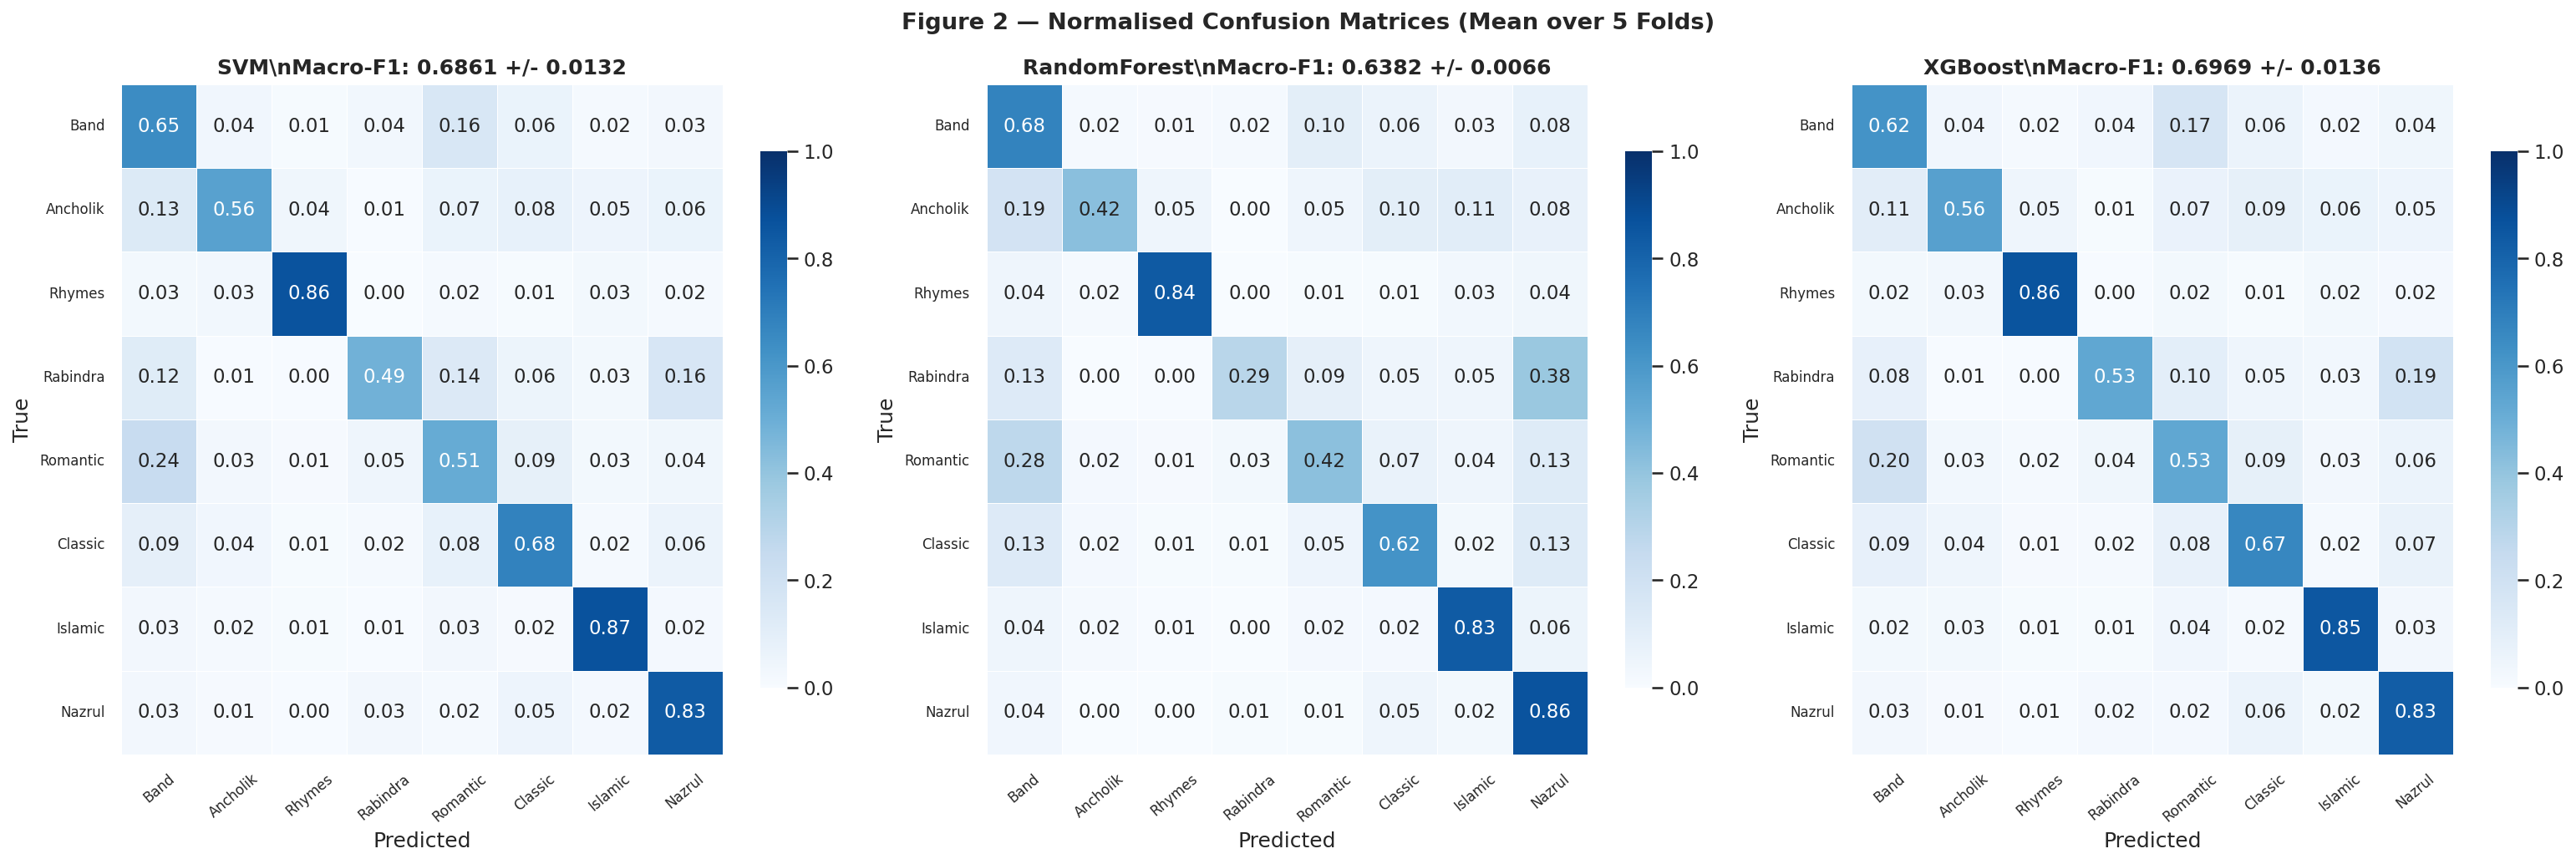

Saved: /kaggle/working/part3_ml/figures/fig02_confusion_matrices.png


In [10]:
# ============================================================
# CELL 10 ▸ Fig 2 — Confusion Matrices
# ============================================================
# Use best fold's predictions (reconstruct from best fold model).
# For simplicity, we report the mean normalised confusion matrix
# (average over all 5 folds).

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
fig.suptitle('Figure 2 — Normalised Confusion Matrices (Mean over 5 Folds)',
             fontweight='bold')

for ax, mname in zip(axes, model_names):
    # Average confusion matrices across folds
    cms = []
    for k in range(N_FOLDS):
        X_tr, y_tr, X_te, y_te, lbl_tr = get_fold_xy(df, feat_cols, k)
        sc_ = StandardScaler(); X_tr_s = sc_.fit_transform(X_tr); X_te_s = sc_.transform(X_te)

        if mname == 'SVM':
            pca_ = PCA(n_components=min(150, X_tr_s.shape[1]), random_state=SEED)
            X_tr_p = pca_.fit_transform(X_tr_s); X_te_p = pca_.transform(X_te_s)
            cw_ = make_class_weight_dict(y_tr)
            clf_ = SVC(kernel='rbf',C=10,gamma='scale',class_weight=cw_,random_state=SEED)
            clf_.fit(X_tr_p, y_tr); y_pred = clf_.predict(X_te_p)
        elif mname == 'RandomForest':
            clf_ = RandomForestClassifier(n_estimators=200,class_weight='balanced_subsample',
                                           n_jobs=-1,random_state=SEED+k)
            clf_.fit(X_tr_s, y_tr); y_pred = clf_.predict(X_te_s)
        else:
            sw_ = make_sample_weights_sqrt(y_tr)
            clf_ = xgb.XGBClassifier(n_estimators=200,max_depth=6,learning_rate=0.05,
                                       objective='multi:softmax',num_class=N_CLASSES,
                                       eval_metric='mlogloss',tree_method='hist',
                                       n_jobs=-1,random_state=SEED+k,verbosity=0)
            clf_.fit(X_tr_s, y_tr, sample_weight=sw_); y_pred = clf_.predict(X_te_s)

        cm = confusion_matrix(y_te, y_pred, labels=list(range(N_CLASSES)))
        with np.errstate(divide='ignore', invalid='ignore'):
            cm_n = np.where(cm.sum(axis=1,keepdims=True)==0, 0,
                            cm.astype(float)/cm.sum(axis=1,keepdims=True))
        cms.append(cm_n)

    mean_cm = np.mean(cms, axis=0)
    sns.heatmap(mean_cm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=SHORT_NAMES, yticklabels=SHORT_NAMES,
                linewidths=0.4, cbar_kws={'shrink':0.8}, ax=ax,
                vmin=0, vmax=1)
    mf1 = CV_RESULTS[mname]['summary']['macro_f1_mean']
    std = CV_RESULTS[mname]['summary']['macro_f1_std']
    ax.set_title(f'{mname}\\nMacro-F1: {mf1:.4f} +/- {std:.4f}',
                 fontweight='bold', fontsize=12)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=40, labelsize=8)
    ax.tick_params(axis='y', rotation=0,  labelsize=8)

plt.tight_layout()
path = os.path.join(FIG_DIR,'fig02_confusion_matrices.png')
plt.savefig(path); plt.show()
print(f'Saved: {path}')

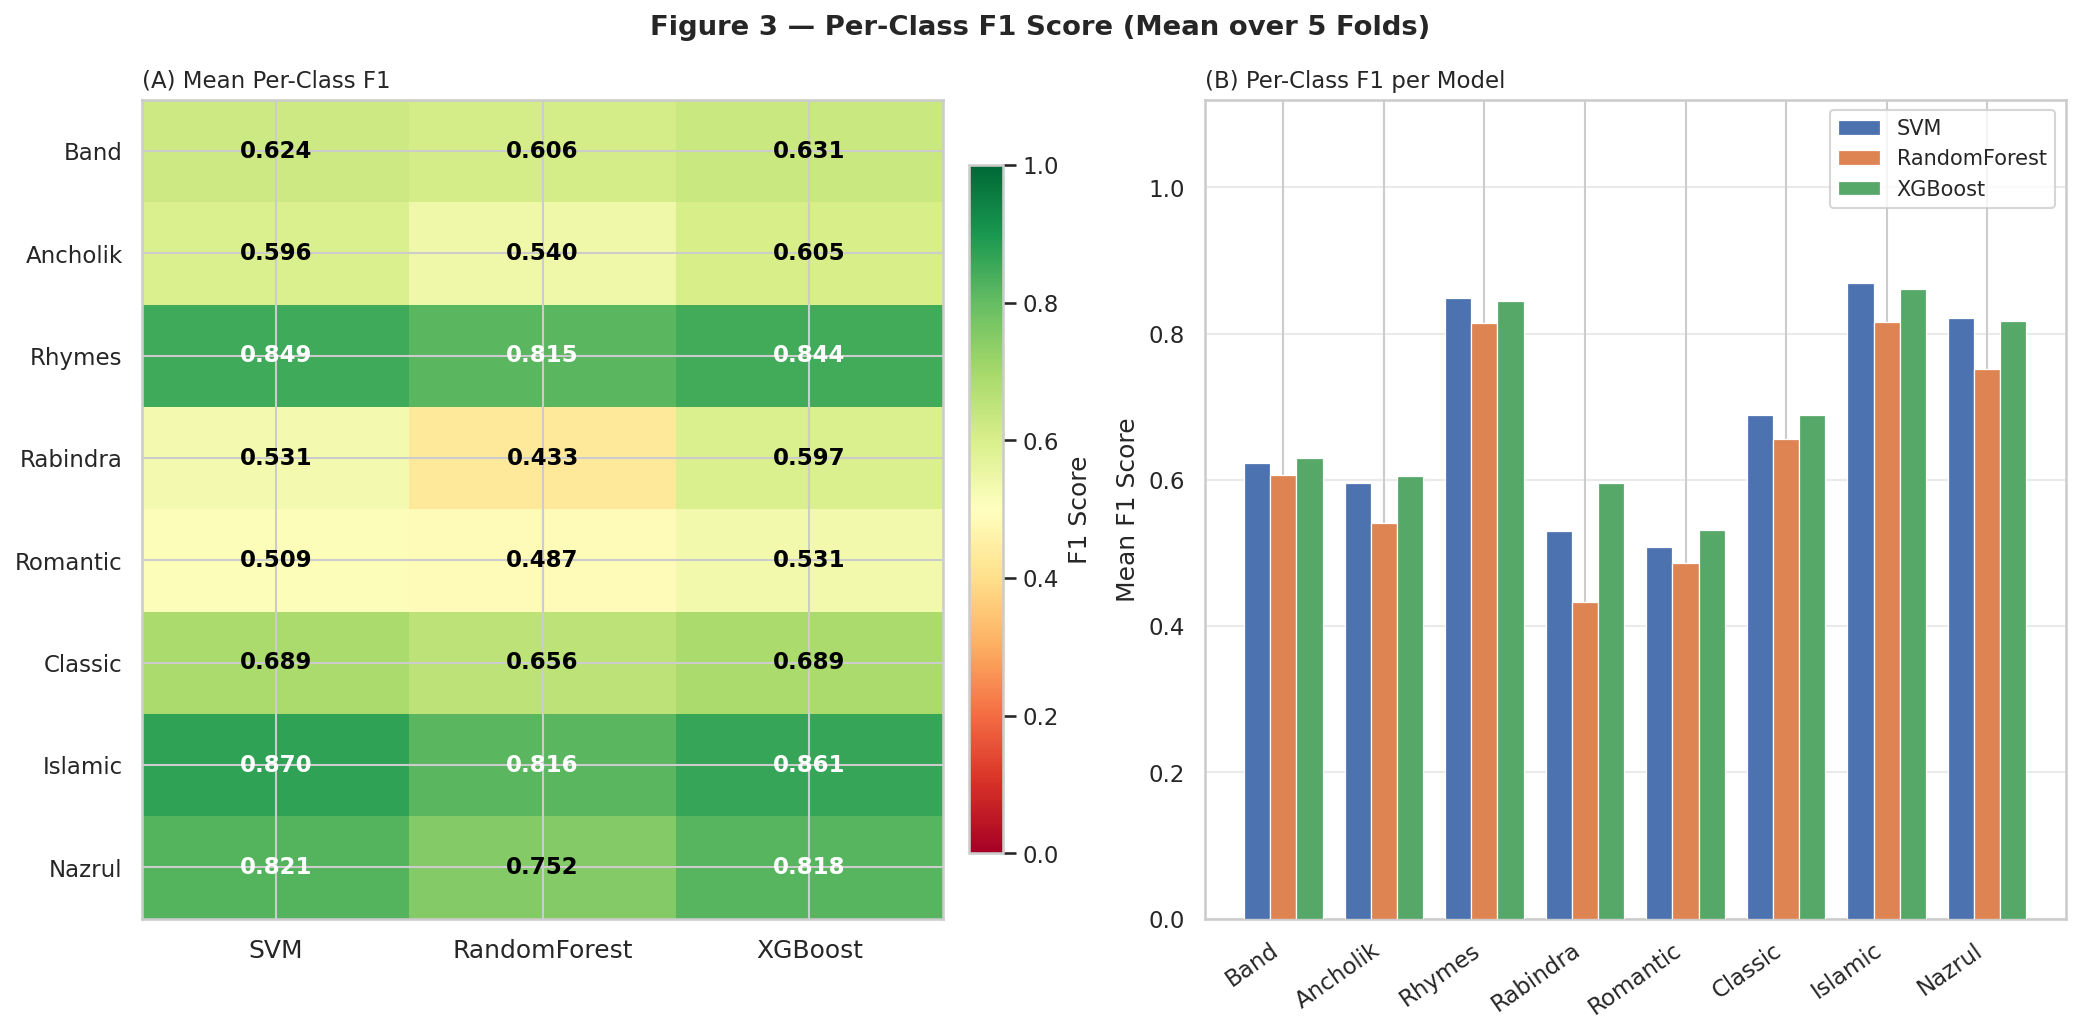

Saved: /kaggle/working/part3_ml/figures/fig03_per_class_f1.png


In [11]:
# ============================================================
# CELL 11 ▸ Fig 3 — Per-Class F1 Heatmap
# ============================================================
f1_matrix = np.zeros((N_CLASSES, 3))
for j, mname in enumerate(model_names):
    for i in range(N_CLASSES):
        vals = [m['per_class_f1'][i] for m in CV_RESULTS[mname]['fold_metrics']]
        f1_matrix[i, j] = np.mean(vals)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
fig.suptitle('Figure 3 — Per-Class F1 Score (Mean over 5 Folds)',
             fontweight='bold')

# Heatmap
ax = axes[0]
im = ax.imshow(f1_matrix, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(3):
        v = f1_matrix[i, j]
        clr = 'white' if v < 0.3 or v > 0.8 else 'black'
        ax.text(j, i, f'{v:.3f}', ha='center', va='center',
                fontsize=11, fontweight='bold', color=clr)
ax.set_xticks(range(3)); ax.set_xticklabels(model_names, fontsize=12)
ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(SHORT_NAMES, fontsize=11)
ax.set_title('(A) Mean Per-Class F1', loc='left', fontsize=11)
plt.colorbar(im, ax=ax, fraction=0.04, pad=0.03, label='F1 Score')

# Grouped bar
ax = axes[1]
x   = np.arange(N_CLASSES); w = 0.26
bar_colors = [MODEL_PAL[m] for m in model_names]
for j, (mname, c) in enumerate(zip(model_names, bar_colors)):
    ax.bar(x+(j-1)*w, f1_matrix[:,j], w, label=mname,
           color=c, edgecolor='white', linewidth=0.6, zorder=3)
ax.set_xticks(x); ax.set_xticklabels(SHORT_NAMES, rotation=35, ha='right')
ax.set_ylabel('Mean F1 Score'); ax.set_ylim(0, 1.12)
ax.set_title('(B) Per-Class F1 per Model', loc='left', fontsize=11)
ax.legend(fontsize=10); ax.yaxis.grid(True, alpha=0.4); ax.set_axisbelow(True)

plt.tight_layout()
path = os.path.join(FIG_DIR,'fig03_per_class_f1.png')
plt.savefig(path); plt.show()
print(f'Saved: {path}')

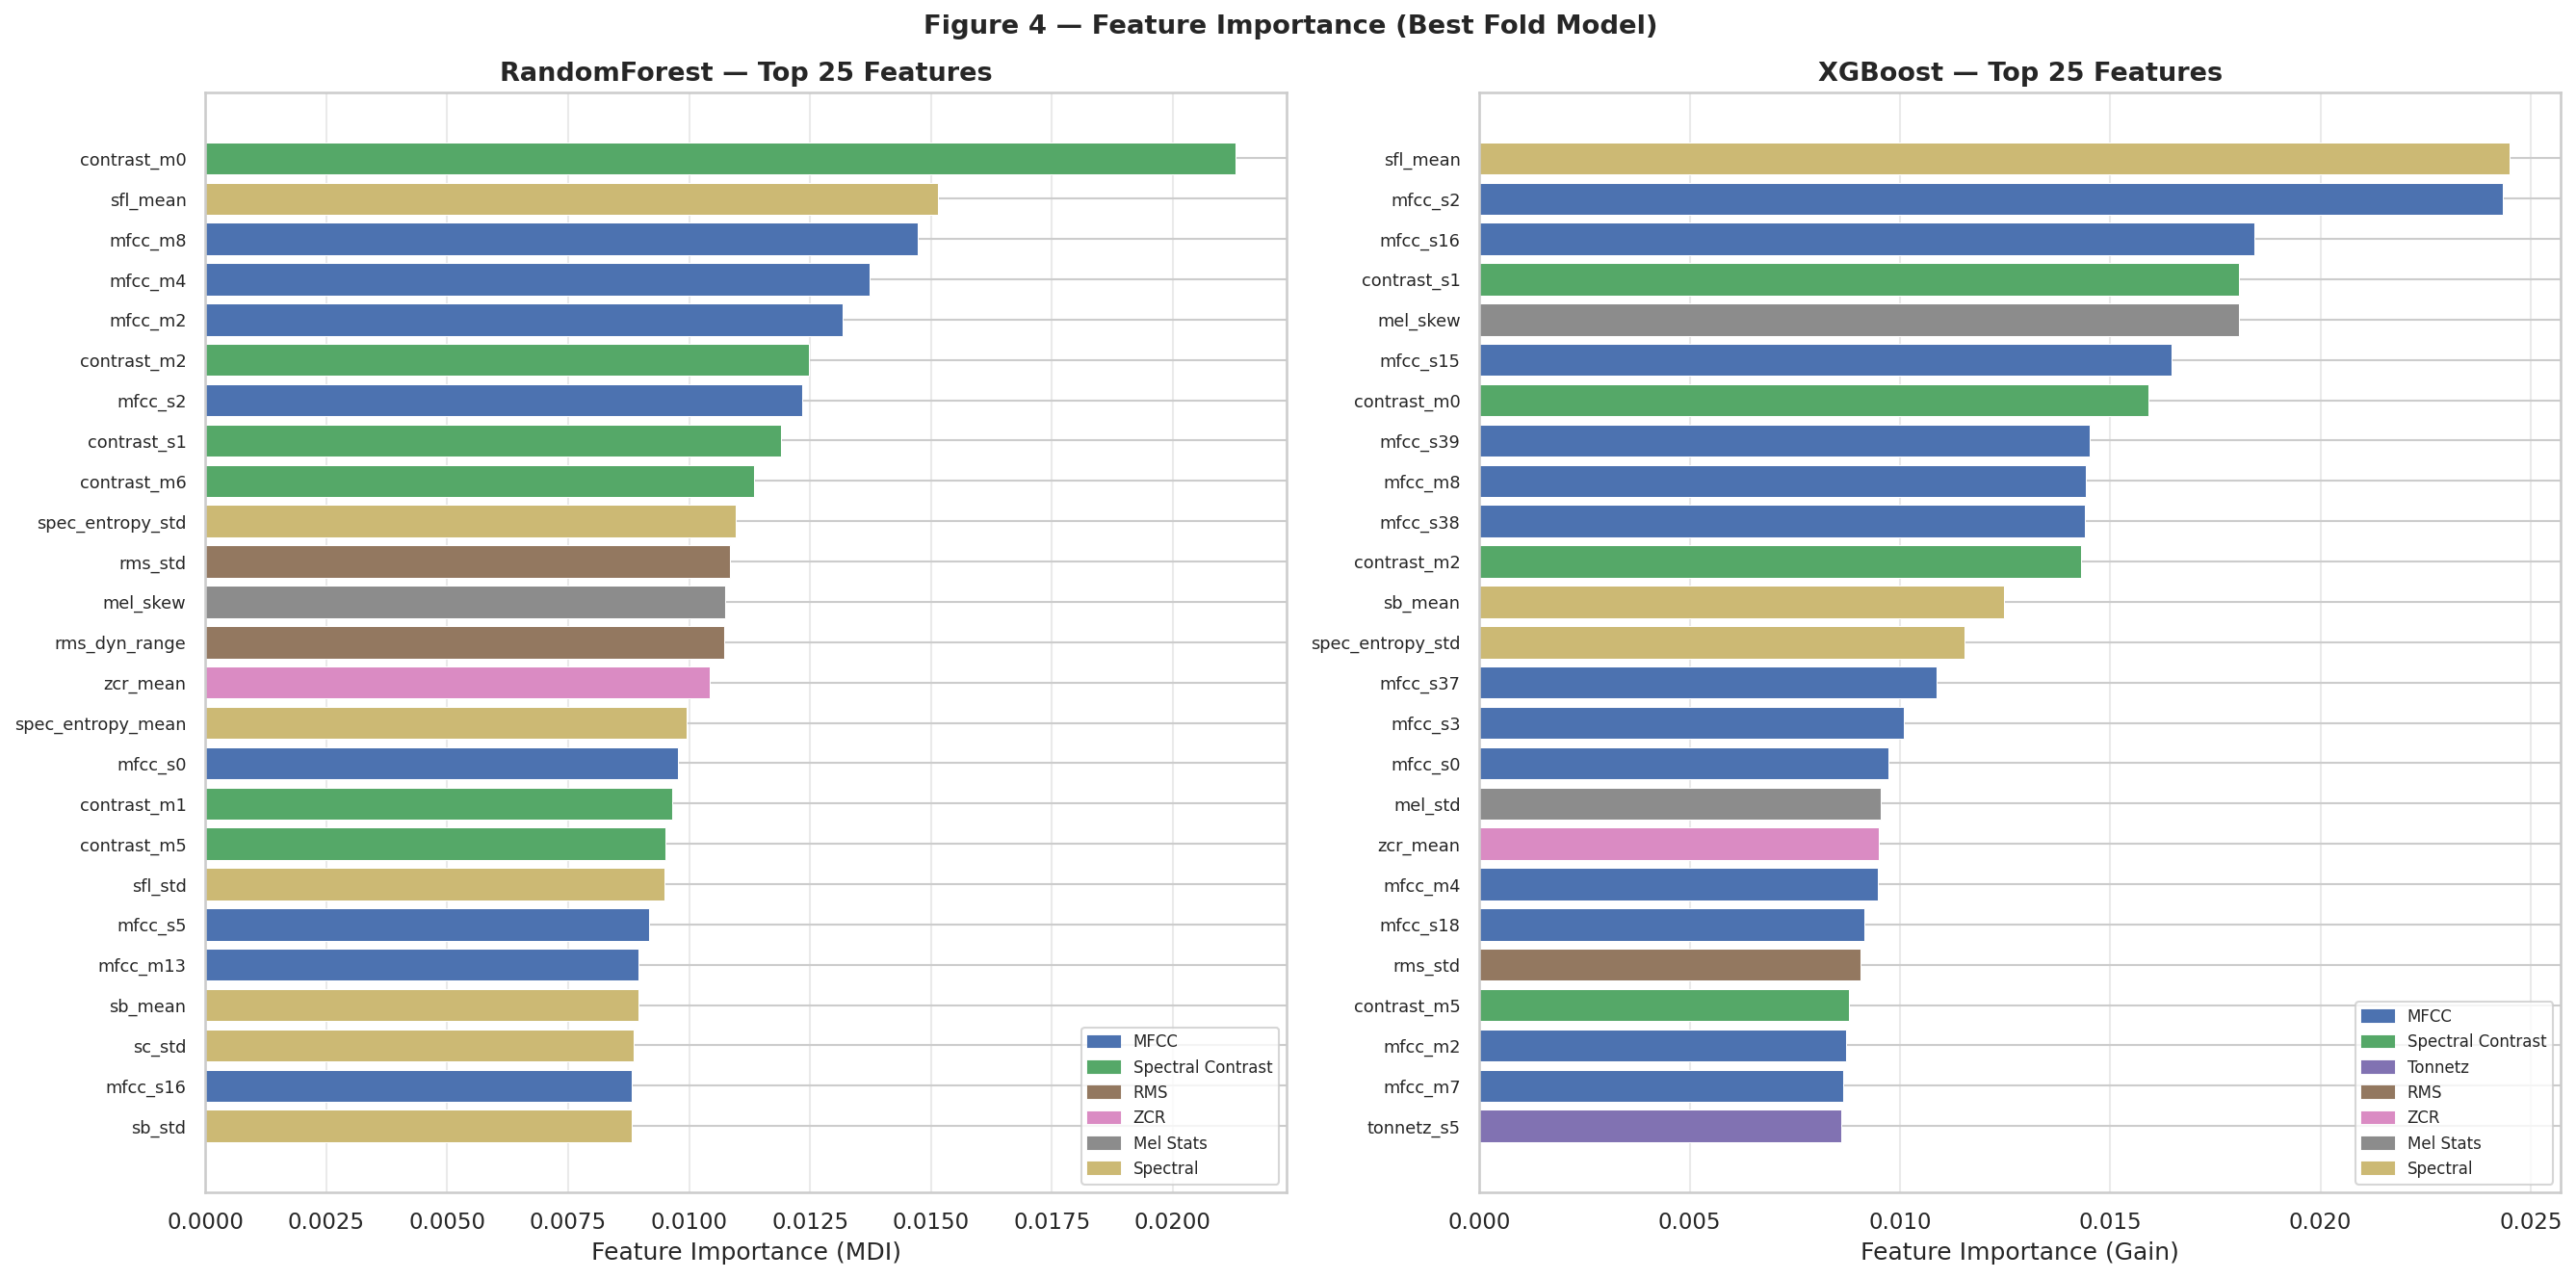

Saved: /kaggle/working/part3_ml/figures/fig04_feature_importance.png


In [12]:
# ============================================================
# CELL 12 ▸ Fig 4 — Feature Importance (RF + XGBoost)
# ============================================================
# Uses the best-fold trained models for feature importance.

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
fig.suptitle('Figure 4 — Feature Importance (Best Fold Model)',
             fontweight='bold')

TOP_N = 25
feat_arr = np.array(feat_cols)

def feat_group(name):
    if name.startswith('mfcc'):     return 'MFCC'
    if name.startswith('dmfcc'):    return 'Delta-MFCC'
    if name.startswith('ddmfcc'):   return 'Delta2-MFCC'
    if name.startswith('chroma'):   return 'Chroma'
    if name.startswith('contrast'): return 'Spectral Contrast'
    if name.startswith('tonnetz'):  return 'Tonnetz'
    if 'rms' in name:               return 'RMS'
    if 'zcr' in name:               return 'ZCR'
    if 'mel' in name:               return 'Mel Stats'
    if any(name.startswith(p) for p in ('sc_','sb_','sro_','sfl_','spec_')): return 'Spectral'
    return 'Temporal'

GROUP_COL = {
    'MFCC':'#4C72B0','Delta-MFCC':'#64B0D0','Delta2-MFCC':'#85C4DB',
    'Chroma':'#DD8452','Spectral Contrast':'#55A868','Tonnetz':'#8172B2',
    'RMS':'#937860','ZCR':'#DA8BC3','Mel Stats':'#8C8C8C','Spectral':'#CCB974',
    'Temporal':'#C44E52',
}

for ax, (mname, imp_attr) in zip(axes, [
    ('RandomForest', best_rf['clf'].feature_importances_),
    ('XGBoost',      best_xgb['clf'].feature_importances_),
]):
    top_idx  = np.argsort(imp_attr)[::-1][:TOP_N]
    top_feat = feat_arr[top_idx]
    top_imp  = imp_attr[top_idx]
    top_grp  = [feat_group(f) for f in top_feat]
    top_clrs = [GROUP_COL.get(g,'gray') for g in top_grp]

    ax.barh(range(TOP_N), top_imp[::-1], color=top_clrs[::-1],
            edgecolor='white', linewidth=0.5)
    ax.set_yticks(range(TOP_N))
    ax.set_yticklabels(top_feat[::-1], fontsize=8.5)
    ax.set_xlabel('Feature Importance (MDI)' if mname=='RandomForest'
                  else 'Feature Importance (Gain)')
    ax.set_title(f'{mname} — Top {TOP_N} Features', fontweight='bold')
    ax.xaxis.grid(True, alpha=0.4); ax.set_axisbelow(True)

    patches = [mpatches.Patch(color=v,label=k) for k,v in GROUP_COL.items()
               if k in set(top_grp)]
    ax.legend(handles=patches, fontsize=8, loc='lower right',
              bbox_to_anchor=(1, 0))

plt.tight_layout()
path = os.path.join(FIG_DIR,'fig04_feature_importance.png')
plt.savefig(path); plt.show()
print(f'Saved: {path}')

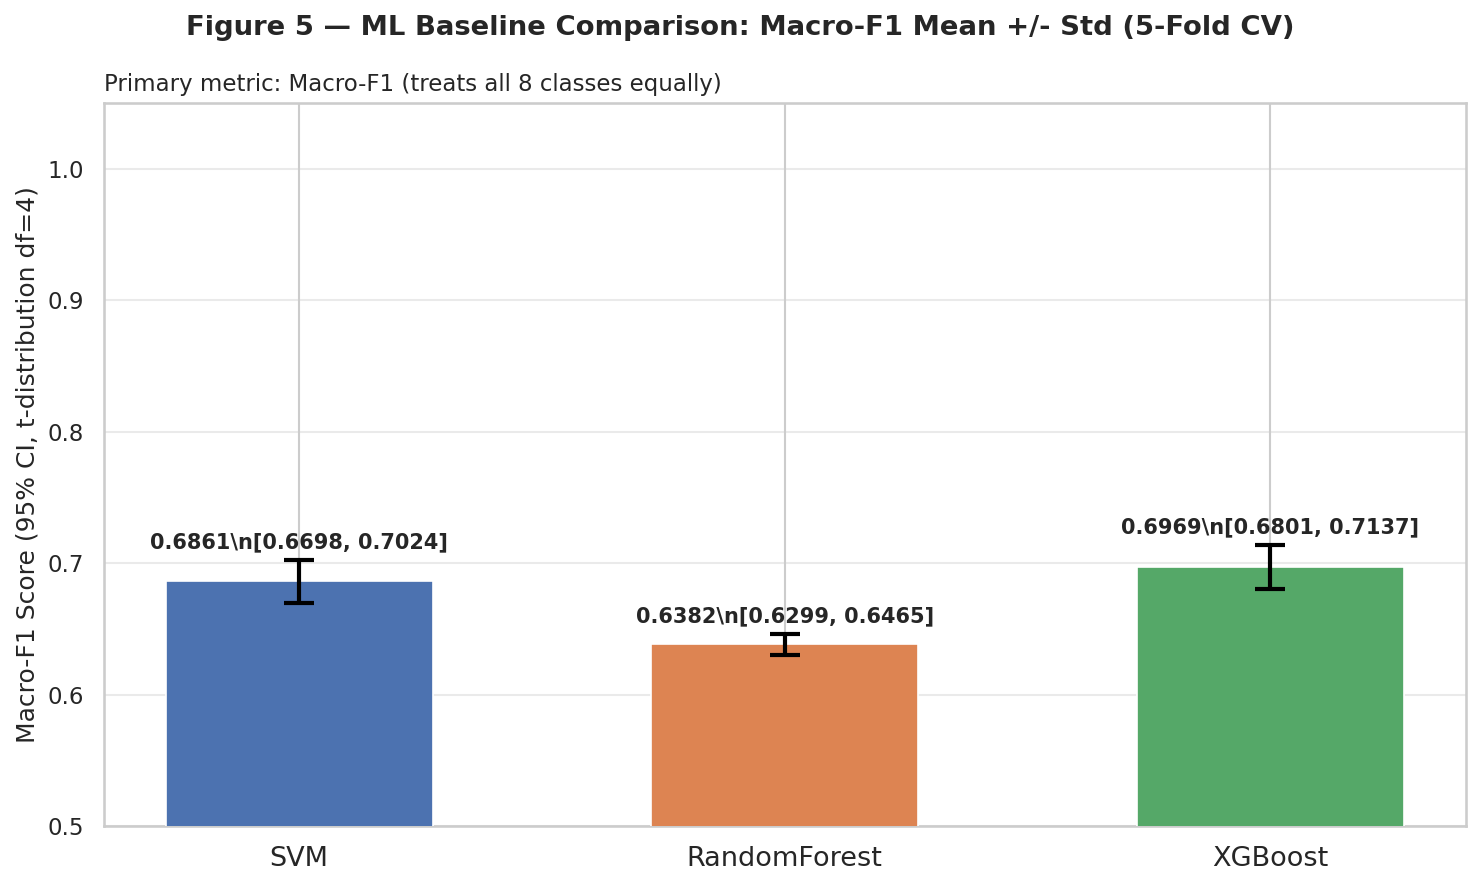

Saved: /kaggle/working/part3_ml/figures/fig05_mean_std_comparison.png


In [13]:
# ============================================================
# CELL 13 ▸ Fig 5 — Mean +/- Std Comparison (Publication)
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle('Figure 5 — ML Baseline Comparison: Macro-F1 Mean +/- Std (5-Fold CV)',
             fontweight='bold')

x = np.arange(n_m)
means  = [CV_RESULTS[m]['summary']['macro_f1_mean'] for m in model_names]
stds   = [CV_RESULTS[m]['summary']['macro_f1_std']  for m in model_names]
ci95s  = [CV_RESULTS[m]['summary']['macro_f1_ci95'] for m in model_names]

bars = ax.bar(x, means, 0.55, color=colors, edgecolor='white',
              linewidth=0.8, zorder=3)
ax.errorbar(x, means, yerr=ci95s, fmt='none', color='black',
            capsize=7, capthick=2, elinewidth=2, zorder=4)

for bar, v, ci in zip(bars, means, ci95s):
    ax.text(bar.get_x()+bar.get_width()/2, v+ci+0.006,
            f'{v:.4f}\\n[{v-ci:.4f}, {v+ci:.4f}]',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xticks(x); ax.set_xticklabels(model_names, fontsize=13)
ax.set_ylabel('Macro-F1 Score (95% CI, t-distribution df=4)')
ax.set_ylim(0.5, 1.05)
ax.yaxis.grid(True, alpha=0.4); ax.set_axisbelow(True)
ax.set_title('Primary metric: Macro-F1 (treats all 8 classes equally)',
             loc='left', fontsize=11)

plt.tight_layout()
path = os.path.join(FIG_DIR,'fig05_mean_std_comparison.png')
plt.savefig(path); plt.show()
print(f'Saved: {path}')

In [14]:
# ============================================================
# CELL 14 ▸ Save Models + ZIP
# ============================================================
zip_path = os.path.join(WORK_DIR, 'part3_ml.zip')
print(f'Creating {zip_path} ...')

with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zf:
    for fname in ['svm.pkl','rf.pkl','xgb.json','xgb_scaler.pkl']:
        fp = os.path.join(MDL_DIR, fname)
        if os.path.exists(fp):
            zf.write(fp, f'models/{fname}')
            print(f'  + models/{fname:<25} {os.path.getsize(fp)/1e6:.1f} MB')
    zf.write(os.path.join(OUT_DIR,'part3_cv_results.json'),'part3_cv_results.json')
    print(f'  + part3_cv_results.json')
    for fname in sorted(os.listdir(FIG_DIR)):
        if fname.endswith('.png'):
            fp = os.path.join(FIG_DIR, fname)
            zf.write(fp, f'figures/{fname}')
            print(f'  + figures/{fname}')

zip_size = os.path.getsize(zip_path)/1e6
best_m = max(CV_RESULTS, key=lambda m: CV_RESULTS[m]['summary']['macro_f1_mean'])
best_f = CV_RESULTS[best_m]['summary']['macro_f1_mean']

print()
print('='*55)
print('  PART 3 COMPLETE')
print('='*55)
print(f'  ZIP : {zip_path}  ({zip_size:.1f} MB)')
print(f'  Best ML model: {best_m}  '
      f'({best_f:.4f} +/- '
      f'{CV_RESULTS[best_m]["summary"]["macro_f1_std"]:.4f})')
print()
print('  → Upload part3_ml.zip as a Kaggle dataset for Part 6.')

Creating /kaggle/working/part3_ml.zip ...
  + models/svm.pkl                   44.5 MB
  + models/rf.pkl                    819.6 MB
  + models/xgb.json                  17.0 MB
  + models/xgb_scaler.pkl            0.0 MB
  + part3_cv_results.json
  + figures/fig01_cv_strip_box.png
  + figures/fig02_confusion_matrices.png
  + figures/fig03_per_class_f1.png
  + figures/fig04_feature_importance.png
  + figures/fig05_mean_std_comparison.png

  PART 3 COMPLETE
  ZIP : /kaggle/working/part3_ml.zip  (282.8 MB)
  Best ML model: XGBoost  (0.6969 +/- 0.0136)

  → Upload part3_ml.zip as a Kaggle dataset for Part 6.
